**Mục đích**: so sánh ba cách xử lý mất cân bằng cho KNN, DT, NB: A không xử lý, B class weight (DT) hoặc prior (NB), C SMOTE đặt trong pipeline. KNN không có phương án B vì không có tham số tương đương. CV 5-fold trên tập train, ngưỡng 0.5.

**Thí nghiệm bổ sung**: tác động của chuẩn hoá lên KNN (K = 21), so sánh có và không có StandardScaler.

In [1]:
import itertools
import joblib
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Đọc và làm sạch dữ liệu
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn"])
y = df["Churn"]

# 2. Tìm tham số chia khớp với split đã lưu từ 01_EDA
saved_train = pd.read_csv("../data/y_train.csv")["Churn"].values
saved_test  = pd.read_csv("../data/y_test.csv")["Churn"].values

found = None
for ts, rs in itertools.product([0.2, 0.25, 0.3], [42, 0, 1, 2, 7, 123, 2024]):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=ts, stratify=y, random_state=rs)
    if len(ytr) == len(saved_train) and (ytr.values == saved_train).all() \
       and (yte.values == saved_test).all():
        found = (ts, rs)
        X_train, X_test, y_train, y_test = Xtr, Xte, ytr, yte
        break

print("Tham số khớp:", found)
assert found is not None, "Không tìm được tham số khớp, xem 01_EDA"

# 3. Preprocessor chưa fit
saved = joblib.load("../data/preprocessing_pipeline.pkl")
preprocessor = clone(saved.named_steps["preprocessor"])
assert clone(preprocessor).fit_transform(X_train).shape == (5634, 40)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if X[c].dtype == "object"]
print(X_train.shape, X_test.shape)
print(y_train.mean().round(4), y_test.mean().round(4))

Tham số khớp: (0.2, 42)
(5634, 19) (1409, 19)
0.2654 0.2654


In [2]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

prep = clone(preprocessor)
assert clone(prep).fit_transform(X_train).shape[1] == 40

K, DEPTH = 21, 3 
VS = 1e-3  

models = {
    "KNN": {
        "A": KNeighborsClassifier(n_neighbors=K),
        "B": None,  
        "C": KNeighborsClassifier(n_neighbors=K),
    },
    "DecisionTree": {
        "A": DecisionTreeClassifier(max_depth=DEPTH, random_state=42),
        "B": DecisionTreeClassifier(max_depth=DEPTH, class_weight="balanced", random_state=42),
        "C": DecisionTreeClassifier(max_depth=DEPTH, random_state=42),
    },
    "NaiveBayes": {
        "A": GaussianNB(var_smoothing=VS),
        "B": GaussianNB(var_smoothing=VS, priors=[0.5, 0.5]),
        "C": GaussianNB(var_smoothing=VS),
    },
}

def build(variant, clf):
    if variant == "C":
        return ImbPipeline([("prep", clone(prep)),
                            ("smote", SMOTE(random_state=42)),
                            ("clf", clf)])
    return Pipeline([("prep", clone(prep)), ("clf", clf)])

scoring = {"recall": "recall", "precision": "precision", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, variants in models.items():
    for v, clf in variants.items():
        if clf is None:
            continue
        res = cross_validate(build(v, clf), X_train, y_train, cv=cv, scoring=scoring)
        row = {"model": name, "variant": v}
        for m in scoring:
            row[m] = f"{res['test_'+m].mean():.3f} ± {res['test_'+m].std():.3f}"
        rows.append(row)

pd.DataFrame(rows)

,model,variant,recall,precision,f1,roc_auc,pr_auc
0,KNN,A,0.582 ± 0.029,0.613 ± 0.020,0.597 ± 0.020,0.829 ± 0.010,0.603 ± 0.024
1,KNN,C,0.826 ± 0.019,0.461 ± 0.006,0.591 ± 0.007,0.818 ± 0.009,0.564 ± 0.022
2,DecisionTree,A,0.364 ± 0.026,0.699 ± 0.020,0.478 ± 0.022,0.816 ± 0.007,0.563 ± 0.015
3,DecisionTree,B,0.776 ± 0.017,0.516 ± 0.027,0.619 ± 0.018,0.815 ± 0.010,0.558 ± 0.020
4,DecisionTree,C,0.734 ± 0.045,0.502 ± 0.014,0.595 ± 0.014,0.795 ± 0.006,0.504 ± 0.008
5,NaiveBayes,A,0.847 ± 0.021,0.459 ± 0.006,0.595 ± 0.008,0.822 ± 0.013,0.615 ± 0.017
6,NaiveBayes,B,0.856 ± 0.019,0.450 ± 0.007,0.590 ± 0.008,0.822 ± 0.013,0.615 ± 0.017
7,NaiveBayes,C,0.840 ± 0.024,0.466 ± 0.011,0.600 ± 0.013,0.822 ± 0.013,0.616 ± 0.017


In [3]:
# Thí nghiệm chuẩn hoá cho KNN (K = 21): bỏ StandardScaler, giữ nguyên các bước còn lại
from sklearn.preprocessing import StandardScaler

steps = [(n, "passthrough" if isinstance(t, StandardScaler) else t, cols)
         for n, t, cols in preprocessor.transformers]
prep_noscale = ColumnTransformer(steps, remainder=preprocessor.remainder)

scale_rows = []
for label, p in [("Có chuẩn hoá", clone(preprocessor)), ("Không chuẩn hoá", prep_noscale)]:
    pipe = Pipeline([("prep", p), ("clf", KNeighborsClassifier(n_neighbors=K))])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    scale_rows.append({"Phương án": label,
                       **{m: round(res["test_" + m].mean(), 3) for m in scoring}})
pd.DataFrame(scale_rows)

,Phương án,recall,precision,f1,roc_auc,pr_auc
0,Có chuẩn hoá,0.582,0.613,0.597,0.829,0.603
1,Không chuẩn hoá,0.376,0.644,0.474,0.781,0.573


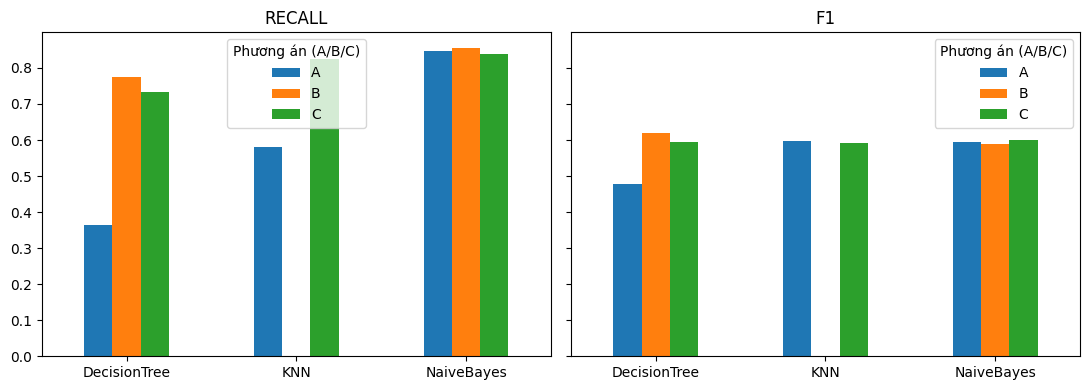

In [4]:
import matplotlib.pyplot as plt

res = pd.DataFrame(rows)
res.to_csv("../data/imbalance_cv_results.csv", index=False)

num = res.copy()
for m in ["recall", "precision", "f1", "roc_auc", "pr_auc"]:
    num[m] = num[m].str.split(" ± ").str[0].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric in zip(axes, ["recall", "f1"]):
    p = num.pivot(index="model", columns="variant", values=metric)
    p.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(metric.upper())
    ax.set_xlabel("")
    ax.legend(title="Phương án (A/B/C)")
plt.tight_layout()
plt.savefig("../figures/06_imbalance_effect.png", dpi=200)
plt.show()

In [5]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

for cw in [None, "balanced"]:
    dt = Pipeline([("prep", clone(preprocessor)),
                   ("clf", DecisionTreeClassifier(max_depth=3, class_weight=cw, random_state=42))])
    dt.fit(X_train, y_train)
    p = dt.predict_proba(X_train)[:, 1]
    print(cw, "| tỉ lệ bị gán churn ở ngưỡng 0.14:", (p >= 0.14).mean().round(3),
          "| số mức xác suất khác nhau:", len(np.unique(p.round(4))))

None | tỉ lệ bị gán churn ở ngưỡng 0.14: 0.608 | số mức xác suất khác nhau: 8
balanced | tỉ lệ bị gán churn ở ngưỡng 0.14: 0.733 | số mức xác suất khác nhau: 8


**Kết quả**:
- Class weight cải thiện rõ nhất cho DT (F1 0.478 → 0.619). 
- SMOTE không cho F1 cao hơn phương án tốt nhất ở KNN và DT; với NB, chênh lệch nằm trong độ lệch chuẩn. NB gần như không đổi vì ở ngưỡng 0.5 đã có Recall 0.847. Chuẩn hoá giúp KNN tăng F1 từ 0.474 lên 0.597.